In [1]:
import pandas as pd
import numpy as np
import os
import threading
import time
import requests

from flask import Flask, request, jsonify, render_template

print("CELL 1 DONE")

CELL 1 DONE


In [2]:
df = pd.read_csv("C:/Users/disha/OneDrive/Desktop/my dataset/supermarket_sales-selected-columns.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(df.columns.tolist())

df

Dataset loaded successfully!
Rows: 1000
Columns: 10
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total']


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785
...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,C,Naypyitaw,Normal,Male,Health and beauty,40.35,1,2.0175,42.3675
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,48.6900,1022.4900
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,1.5920,33.4320
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,3.2910,69.1110


In [3]:
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785


In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

df_clean = df.copy()

numeric_cols = [
    "Unit price",
    "Quantity",
    "Tax 5%",
    "Total"
]

Missing Values:
Invoice ID       0
Branch           0
City             0
Customer type    0
Gender           0
Product line     0
Unit price       0
Quantity         0
Tax 5%           0
Total            0
dtype: int64

Duplicate Rows:
0

Data Types:
Invoice ID        object
Branch            object
City              object
Customer type     object
Gender            object
Product line      object
Unit price       float64
Quantity           int64
Tax 5%           float64
Total            float64
dtype: object


In [5]:
import re
import pandas as pd
import numpy as np


def nlp_data_analysis(question, data=None):

    if data is None:
        data = df_clean

    q = question.lower().strip()

    # =====================================================
    # 1. DATASET INFORMATION
    # =====================================================

    if any(x in q for x in [
        "column", "columns", "fields", "variables"
    ]):

        return (
            f"The dataset contains {len(data.columns)} columns: "
            + ", ".join(data.columns)
        )

    if any(x in q for x in [
        "how many rows",
        "number of rows",
        "records",
        "transactions"
    ]):

        if "transaction" in q:
            return f"There are {len(data):,} transactions."

        return f"The dataset contains {len(data):,} rows."

    if "shape" in q or "size of dataset" in q:

        return (
            f"The dataset has {data.shape[0]:,} rows "
            f"and {data.shape[1]} columns."
        )

    # =====================================================
    # 2. MISSING VALUES
    # =====================================================

    if any(x in q for x in [
        "missing",
        "null",
        "empty values",
        "missing values"
    ]):

        missing = data.isnull().sum()
        total_missing = int(missing.sum())

        if total_missing == 0:
            return "There are no missing values in the dataset."

        result = missing[missing > 0].to_dict()

        return (
            f"There are {total_missing} missing values. "
            f"By column: {result}"
        )

    # =====================================================
    # 3. DUPLICATES
    # =====================================================

    if "duplicate" in q:

        count = int(data.duplicated().sum())

        return (
            f"There are {count} duplicate rows "
            f"in the dataset."
        )

    # =====================================================
    # 4. TOTAL SALES
    # =====================================================

    if (
        ("total" in q and "sale" in q)
        or "total revenue" in q
        or "overall sales" in q
        or "overall revenue" in q
    ):

        value = data["Total"].sum()

        return f"Total sales are {value:,.2f}."

    # =====================================================
    # 5. AVERAGE SALES
    # =====================================================

    if (
        "average sale" in q
        or "average sales" in q
        or "mean sale" in q
        or "average transaction" in q
    ):

        value = data["Total"].mean()

        return f"The average sale is {value:,.2f}."

    # =====================================================
    # 6. HIGHEST SALE
    # =====================================================

    if any(x in q for x in [
        "highest sale",
        "maximum sale",
        "max sale",
        "largest sale",
        "biggest sale",
        "highest total"
    ]):

        value = data["Total"].max()

        return f"The highest sale is {value:,.2f}."

    # =====================================================
    # 7. LOWEST SALE
    # =====================================================

    if any(x in q for x in [
        "lowest sale",
        "minimum sale",
        "min sale",
        "smallest sale",
        "lowest total"
    ]):

        value = data["Total"].min()

        return f"The lowest sale is {value:,.2f}."

    # =====================================================
    # 8. TOTAL QUANTITY
    # =====================================================

    if (
        "total quantity" in q
        or "quantity sold" in q
        or "units sold" in q
        or "total units" in q
    ):

        value = data["Quantity"].sum()

        return f"Total quantity sold is {value:,.0f} units."

    # =====================================================
    # 9. AVERAGE QUANTITY
    # =====================================================

    if (
        "average quantity" in q
        or "mean quantity" in q
    ):

        value = data["Quantity"].mean()

        return f"The average quantity per transaction is {value:,.2f}."

    # =====================================================
    # 10. HIGHEST QUANTITY
    # =====================================================

    if any(x in q for x in [
        "highest quantity",
        "maximum quantity",
        "most quantity"
    ]):

        value = data["Quantity"].max()

        return f"The highest quantity in a transaction is {value:,.0f}."

    # =====================================================
    # 11. SALES BY CITY
    # =====================================================

    if "city" in q and (
        "sales" in q
        or "sale" in q
        or "revenue" in q
    ):

        grouped = (
            data.groupby("City")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        if any(x in q for x in [
            "highest",
            "best",
            "top",
            "most"
        ]):

            city = grouped.index[0]

            return (
                f"{city} has the highest sales "
                f"with {grouped.iloc[0]:,.2f}."
            )

        if any(x in q for x in [
            "lowest",
            "worst",
            "least"
        ]):

            city = grouped.index[-1]

            return (
                f"{city} has the lowest sales "
                f"with {grouped.iloc[-1]:,.2f}."
            )

        return (
            "Sales by city:\n"
            + "\n".join(
                f"{city}: {value:,.2f}"
                for city, value in grouped.items()
            )
        )

    # =====================================================
    # 12. QUANTITY BY CITY
    # =====================================================

    if "city" in q and "quantity" in q:

        grouped = (
            data.groupby("City")["Quantity"]
            .sum()
            .sort_values(ascending=False)
        )

        city = grouped.index[0]

        return (
            f"{city} has the highest quantity sold "
            f"with {grouped.iloc[0]:,.0f} units.\n\n"
            + "\n".join(
                f"{c}: {v:,.0f}"
                for c, v in grouped.items()
            )
        )

    # =====================================================
    # 13. SALES BY GENDER
    # =====================================================

    if "gender" in q or "male" in q or "female" in q:

        grouped = (
            data.groupby("Gender")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        if "female" in q and "male" not in q:

            value = grouped.get("Female", 0)

            return f"Female customers generated {value:,.2f} in sales."

        if "male" in q and "female" not in q:

            value = grouped.get("Male", 0)

            return f"Male customers generated {value:,.2f} in sales."

        if "compare" in q:

            return (
                "Sales by gender:\n"
                + "\n".join(
                    f"{g}: {v:,.2f}"
                    for g, v in grouped.items()
                )
            )

        gender = grouped.index[0]

        return (
            f"{gender} generated the highest sales "
            f"with {grouped.iloc[0]:,.2f}."
        )

    # =====================================================
    # 14. PRODUCT LINE
    # =====================================================

    if (
        "product" in q
        or "product line" in q
        or "category" in q
    ):

        grouped = (
            data.groupby("Product line")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        if any(x in q for x in [
            "highest",
            "best",
            "top",
            "most"
        ]):

            product = grouped.index[0]

            return (
                f"{product} has the highest sales "
                f"with {grouped.iloc[0]:,.2f}."
            )

        if any(x in q for x in [
            "lowest",
            "least",
            "worst"
        ]):

            product = grouped.index[-1]

            return (
                f"{product} has the lowest sales "
                f"with {grouped.iloc[-1]:,.2f}."
            )

        return (
            "Sales by product line:\n"
            + "\n".join(
                f"{p}: {v:,.2f}"
                for p, v in grouped.items()
            )
        )

    # =====================================================
    # 15. TOP N
    # =====================================================

    match = re.search(
        r"top\s+(\d+)",
        q
    )

    if match:

        n = int(match.group(1))

        if "city" in q:

            grouped = (
                data.groupby("City")["Total"]
                .sum()
                .sort_values(ascending=False)
                .head(n)
            )

            return (
                f"Top {n} cities by sales:\n"
                + "\n".join(
                    f"{i+1}. {k}: {v:,.2f}"
                    for i, (k, v)
                    in enumerate(grouped.items())
                )
            )

        if "product" in q:

            grouped = (
                data.groupby("Product line")["Total"]
                .sum()
                .sort_values(ascending=False)
                .head(n)
            )

            return (
                f"Top {n} products by sales:\n"
                + "\n".join(
                    f"{i+1}. {k}: {v:,.2f}"
                    for i, (k, v)
                    in enumerate(grouped.items())
                )
            )

    # =====================================================
    # 16. BOTTOM N
    # =====================================================

    match = re.search(
        r"bottom\s+(\d+)",
        q
    )

    if match:

        n = int(match.group(1))

        if "city" in q:

            grouped = (
                data.groupby("City")["Total"]
                .sum()
                .sort_values()
                .head(n)
            )

            return (
                f"Bottom {n} cities by sales:\n"
                + "\n".join(
                    f"{i+1}. {k}: {v:,.2f}"
                    for i, (k, v)
                    in enumerate(grouped.items())
                )
            )

        if "product" in q:

            grouped = (
                data.groupby("Product line")["Total"]
                .sum()
                .sort_values()
                .head(n)
            )

            return (
                f"Bottom {n} products by sales:\n"
                + "\n".join(
                    f"{i+1}. {k}: {v:,.2f}"
                    for i, (k, v)
                    in enumerate(grouped.items())
                )
            )

    # =====================================================
    # 17. GENERAL INSIGHTS
    # =====================================================

    if any(x in q for x in [
        "insight",
        "insights",
        "summary",
        "analyze",
        "analysis",
        "performance",
        "tell me about the dataset"
    ]):

        city_sales = (
            data.groupby("City")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        product_sales = (
            data.groupby("Product line")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        gender_sales = (
            data.groupby("Gender")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        return (
            "Key Business Insights:\n\n"
            f"• Total sales: {data['Total'].sum():,.2f}\n"
            f"• Average sale: {data['Total'].mean():,.2f}\n"
            f"• Highest sale: {data['Total'].max():,.2f}\n"
            f"• Best city: {city_sales.index[0]} "
            f"({city_sales.iloc[0]:,.2f})\n"
            f"• Best product: {product_sales.index[0]} "
            f"({product_sales.iloc[0]:,.2f})\n"
            f"• Top gender: {gender_sales.index[0]} "
            f"({gender_sales.iloc[0]:,.2f})"
        )

    # =====================================================
    # 18. FALLBACK
    # =====================================================

    return (
        "I understand the question, but I need more detail. "
        "You can ask about sales, quantity, city, gender, "
        "product line, transactions, averages, highest/lowest "
        "values, top/bottom rankings, missing values, "
        "duplicates, or dataset information."
    )


print("NLP DATA ANALYST READY")

NLP DATA ANALYST READY


In [6]:
questions = [
    "What is the total sales?",
    "What is the average sale?",
    "What is the highest sale?",
    "Which city has the highest sales?",
    "Which product line has the highest sales?",
    "Compare male and female sales",
    "Show top 3 cities",
    "Show top 5 products",
    "What is the total quantity?",
    "Are there missing values?",
    "Are there duplicate rows?",
    "Give me the main business insights"
]

for q in questions:
    print("\nQUESTION:", q)
    print(nlp_data_analysis(q))


QUESTION: What is the total sales?
Total sales are 322,966.75.

QUESTION: What is the average sale?
The average sale is 322.97.

QUESTION: What is the highest sale?
The highest sale is 1,042.65.

QUESTION: Which city has the highest sales?
The highest sale is 1,042.65.

QUESTION: Which product line has the highest sales?
The highest sale is 1,042.65.

QUESTION: Compare male and female sales
Sales by gender:
Female: 167,882.92
Male: 155,083.82

QUESTION: Show top 3 cities
I understand the question, but I need more detail. You can ask about sales, quantity, city, gender, product line, transactions, averages, highest/lowest values, top/bottom rankings, missing values, duplicates, or dataset information.

QUESTION: Show top 5 products
Food and beverages has the highest sales with 56,144.84.

QUESTION: What is the total quantity?
Total quantity sold is 5,510 units.

QUESTION: Are there missing values?
There are no missing values in the dataset.

QUESTION: Are there duplicate rows?
There ar

In [7]:
def get_dashboard_data(df):

    data = {}

    # =========================
    # KPI
    # =========================

    data["total_sales"] = round(
        df["Total"].sum(), 2
    )

    data["average_sale"] = round(
        df["Total"].mean(), 2
    ) if len(df) > 0 else 0

    data["highest_sale"] = round(
        df["Total"].max(), 2
    ) if len(df) > 0 else 0

    data["total_quantity"] = int(
        df["Quantity"].sum()
    )

    data["transactions"] = int(
        len(df)
    )


    # =========================
    # SALES BY CITY
    # =========================

    data["sales_by_city"] = (
        df.groupby("City")["Total"]
        .sum()
        .round(2)
        .to_dict()
    )


    # =========================
    # SALES BY BRANCH
    # =========================

    data["sales_by_branch"] = (
        df.groupby("Branch")["Total"]
        .sum()
        .round(2)
        .to_dict()
    )


    # =========================
    # SALES BY GENDER
    # =========================

    data["sales_by_gender"] = (
        df.groupby("Gender")["Total"]
        .sum()
        .round(2)
        .to_dict()
    )


    # =========================
    # SALES BY PRODUCT
    # =========================

    data["sales_by_product"] = (
        df.groupby("Product line")["Total"]
        .sum()
        .round(2)
        .to_dict()
    )


    # =========================
    # QUANTITY BY CITY
    # =========================

    data["quantity_by_city"] = (
        df.groupby("City")["Quantity"]
        .sum()
        .astype(int)
        .to_dict()
    )


    return data


print("✅ get_dashboard_data() created")

✅ get_dashboard_data() created


In [8]:
def apply_filters(
    data,
    city="All",
    gender="All",
    product="All"
):

    filtered_df = data.copy()

    # City filter
    if city != "All":
        filtered_df = filtered_df[
            filtered_df["City"] == city
        ]

    # Gender filter
    if gender != "All":
        filtered_df = filtered_df[
            filtered_df["Gender"] == gender
        ]

    # Product filter
    if product != "All":
        filtered_df = filtered_df[
            filtered_df["Product line"] == product
        ]

    return filtered_df


print("✅ Filter function created")

✅ Filter function created


In [9]:
test_df = apply_filters(
    df_clean,
    city="Mandalay",
    gender="Female",
    product="All"
)

print("Rows after filter:", len(test_df))
print(test_df[[
    "City",
    "Gender",
    "Product line",
    "Total"
]].head())

Rows after filter: 162
        City  Gender         Product line    Total
9   Mandalay  Female   Food and beverages  172.746
10  Mandalay  Female  Fashion accessories   60.816
15  Mandalay  Female    Sports and travel  590.436
19  Mandalay  Female   Home and lifestyle   84.630
28  Mandalay  Female   Food and beverages  463.890


In [10]:
test_df = apply_filters(
    df_clean,
    city="Mandalay",
    gender="Female",
    product="Food and beverages"
)

print("Rows:", len(test_df))
print("Sales:", round(test_df["Total"].sum(), 2))
print("Quantity:", test_df["Quantity"].sum())

Rows: 29
Sales: 10510.0
Quantity: 169


In [11]:
def ask(self, question):

    q = question.lower().strip()

    # =====================================================
    # BASIC SALES
    # =====================================================

    if "total sales" in q or "sales total" in q:
        return f"Total sales are {self.df['Total'].sum():.2f}"

    if "average sale" in q or "average sales" in q:
        return f"Average sale is {self.df['Total'].mean():.2f}"

    if (
        "highest total" in q
        or "highest sale" in q
        or "maximum sale" in q
        or "max sale" in q
    ):
        return f"Highest sale is {self.df['Total'].max():.2f}"

    if (
        "minimum total" in q
        or "minimum sale" in q
        or "lowest total" in q
        or "lowest sale" in q
        or "min sale" in q
    ):
        return f"Minimum sale is {self.df['Total'].min():.2f}"

    # =====================================================
    # TRANSACTIONS
    # =====================================================

    if (
        "transactions" in q
        or "number of transactions" in q
        or "how many transactions" in q
    ):
        return f"There are {len(self.df)} transactions."

    # =====================================================
    # QUANTITY
    # =====================================================

    if "total quantity" in q or "quantity sold" in q:
        return f"Total quantity sold is {self.df['Quantity'].sum()}"

    # =====================================================
    # SALES BY CITY
    # =====================================================

    if "sales by city" in q:

        result = (
            self.df.groupby("City")["Total"]
            .sum()
            .round(2)
            .to_dict()
        )

        return result

    # =====================================================
    # QUANTITY BY CITY
    # =====================================================

    if "quantity by city" in q:

        result = (
            self.df.groupby("City")["Quantity"]
            .sum()
            .to_dict()
        )

        return result

    # =====================================================
    # HIGHEST QUANTITY CITY
    # =====================================================

    if (
        "city has the highest quantity" in q
        or "highest quantity city" in q
        or "city with highest quantity" in q
    ):

        data = self.df.groupby("City")["Quantity"].sum()

        city = data.idxmax()
        quantity = data.max()

        return f"{city} has the highest quantity with {quantity} units."

    # =====================================================
    # LOWEST QUANTITY CITY
    # =====================================================

    if (
        "city has the lowest quantity" in q
        or "lowest quantity city" in q
    ):

        data = self.df.groupby("City")["Quantity"].sum()

        city = data.idxmin()
        quantity = data.min()

        return f"{city} has the lowest quantity with {quantity} units."

    # =====================================================
    # SALES BY GENDER
    # =====================================================

    if "sales by gender" in q:

        result = (
            self.df.groupby("Gender")["Total"]
            .sum()
            .round(2)
            .to_dict()
        )

        return result

    # =====================================================
    # WHICH GENDER PURCHASED MORE
    # =====================================================

    if (
        "gender purchased more" in q
        or "which gender purchased more" in q
        or "gender bought more" in q
    ):

        data = self.df.groupby("Gender")["Quantity"].sum()

        gender = data.idxmax()
        quantity = data.max()

        return f"{gender} purchased more products with {quantity} units."

    # =====================================================
    # QUANTITY BY GENDER
    # =====================================================

    if "quantity by gender" in q:

        result = (
            self.df.groupby("Gender")["Quantity"]
            .sum()
            .to_dict()
        )

        return result

    # =====================================================
    # SALES BY PRODUCT LINE
    # =====================================================

    if (
        "sales by product line" in q
        or "sales by product" in q
    ):

        result = (
            self.df.groupby("Product line")["Total"]
            .sum()
            .round(2)
            .to_dict()
        )

        return result

    # =====================================================
    # QUANTITY BY PRODUCT LINE
    # =====================================================

    if (
        "quantity by product line" in q
        or "quantity by product" in q
    ):

        result = (
            self.df.groupby("Product line")["Quantity"]
            .sum()
            .to_dict()
        )

        return result

    # =====================================================
    # HIGHEST SALES PRODUCT
    # =====================================================

    if (
        "highest sales product" in q
        or "highest sales product line" in q
        or "product line has the highest sales" in q
    ):

        data = self.df.groupby("Product line")["Total"].sum()

        product = data.idxmax()
        sales = data.max()

        return f"{product} has the highest sales with {sales:.2f}."

    # =====================================================
    # HIGHEST QUANTITY PRODUCT
    # =====================================================

    if (
        "product line has the highest quantity" in q
        or "highest quantity product" in q
        or "highest quantity product line" in q
    ):

        data = self.df.groupby("Product line")["Quantity"].sum()

        product = data.idxmax()
        quantity = data.max()

        return f"{product} has the highest quantity with {quantity} units."

    # =====================================================
    # TOP 3 PRODUCT LINES BY SALES
    # =====================================================

    if (
        "top 3 product" in q
        or "top three product" in q
        or "top 3 product line" in q
        or "top three product line" in q
    ):

        data = (
            self.df.groupby("Product line")["Total"]
            .sum()
            .sort_values(ascending=False)
            .head(3)
            .round(2)
            .to_dict()
        )

        return data

    # =====================================================
    # TOP 5 PRODUCT LINES
    # =====================================================

    if (
        "top 5 product" in q
        or "top five product" in q
    ):

        data = (
            self.df.groupby("Product line")["Total"]
            .sum()
            .sort_values(ascending=False)
            .head(5)
            .round(2)
            .to_dict()
        )

        return data

    # =====================================================
    # BRANCH
    # =====================================================

    if "sales by branch" in q:

        result = (
            self.df.groupby("Branch")["Total"]
            .sum()
            .round(2)
            .to_dict()
        )

        return result

    # =====================================================
    # CUSTOMER TYPE
    # =====================================================

    if "sales by customer type" in q:

        result = (
            self.df.groupby("Customer type")["Total"]
            .sum()
            .round(2)
            .to_dict()
        )

        return result

    # =====================================================
    # DATASET INFORMATION
    # =====================================================

    if (
        "dataset" in q
        or "data information" in q
        or "how many rows" in q
        or "how many columns" in q
        or "column names" in q
    ):

        return {
            "rows": len(self.df),
            "columns": len(self.df.columns),
            "column_names": self.df.columns.tolist()
        }

    # =====================================================
    # MISSING VALUES
    # =====================================================

    if (
        "missing values" in q
        or "null values" in q
    ):

        return self.df.isnull().sum().to_dict()

    # =====================================================
    # DUPLICATES
    # =====================================================

    if "duplicate" in q:

        return f"There are {self.df.duplicated().sum()} duplicate rows."

    # =====================================================
    # FALLBACK
    # =====================================================

    return (
        "I could not understand the question. "
        "Please ask a question related to sales, "
        "quantity, city, gender, product line, "
        "transactions, branch, customer type, "
        "or dataset information."
    )

In [12]:
class AIDataAnalyst:

    def __init__(self, df):
        self.df = df

    def ask(self, question):

        question = question.lower().strip()

        # -----------------------------
        # MINIMUM TOTAL
        # -----------------------------
        if "minimum total" in question or "lowest total" in question:
            return f"Minimum total is {self.df['Total'].min():.2f}"

        # -----------------------------
        # HIGHEST TOTAL
        # -----------------------------
        if "highest total" in question or "maximum total" in question:
            return f"Highest total is {self.df['Total'].max():.2f}"

        # -----------------------------
        # TRANSACTIONS
        # -----------------------------
        if "transactions" in question:
            return f"Total transactions are {len(self.df)}"

        # -----------------------------
        # SALES BY CITY
        # -----------------------------
        if "sales by city" in question:
            result = self.df.groupby("City")["Total"].sum().round(2)
            return result.to_dict()

        # -----------------------------
        # QUANTITY BY CITY
        # -----------------------------
        if "quantity by city" in question:
            result = self.df.groupby("City")["Quantity"].sum()
            return result.to_dict()

        # -----------------------------
        # HIGHEST QUANTITY CITY
        # -----------------------------
        if "highest quantity" in question:
            result = self.df.groupby("City")["Quantity"].sum()
            city = result.idxmax()
            quantity = result.max()

            return f"{city} has the highest quantity with {quantity} products."

        # -----------------------------
        # SALES BY PRODUCT LINE
        # -----------------------------
        if "sales by product line" in question:
            result = self.df.groupby("Product line")["Total"].sum().round(2)
            return result.to_dict()

        # -----------------------------
        # HIGHEST QUANTITY PRODUCT
        # -----------------------------
        if "product line" in question and "highest quantity" in question:
            result = self.df.groupby("Product line")["Quantity"].sum()
            product = result.idxmax()
            quantity = result.max()

            return f"{product} has the highest quantity with {quantity} products."

        # -----------------------------
        # TOP 3 PRODUCT LINES BY SALES
        # -----------------------------
        if "top 3 product" in question:

            result = (
                self.df.groupby("Product line")["Total"]
                .sum()
                .sort_values(ascending=False)
                .head(3)
                .round(2)
            )

            return result.to_dict()

        # -----------------------------
        # SALES BY GENDER
        # -----------------------------
        if "sales by gender" in question:
            result = self.df.groupby("Gender")["Total"].sum().round(2)
            return result.to_dict()

        # -----------------------------
        # GENDER PURCHASED MORE
        # -----------------------------
        if "gender" in question and (
            "purchased more" in question
            or "more products" in question
        ):

            result = self.df.groupby("Gender")["Quantity"].sum()

            gender = result.idxmax()
            quantity = result.max()

            return f"{gender} purchased more products with {quantity} items."

        # -----------------------------
        # AVERAGE SALE
        # -----------------------------
        if "average sale" in question:
            return f"Average sale is {self.df['Total'].mean():.2f}"

        # -----------------------------
        # FALLBACK
        # -----------------------------
        return "Sorry, I don't support this question yet."

In [13]:
print(AIDataAnalyst)

<class '__main__.AIDataAnalyst'>


In [14]:
analyst = AIDataAnalyst(df_clean)

print("AIDataAnalyst created successfully")

AIDataAnalyst created successfully


In [15]:
# Test
print(analyst.ask("What is the minimum total?"))
print(analyst.ask("How many transactions are there?"))
print(analyst.ask("Show sales by city."))
print(analyst.ask("Show quantity by city."))
print(analyst.ask("Which city has the highest quantity?"))
print(analyst.ask("Show sales by product line."))
print(analyst.ask("Which product line has the highest quantity?"))
print(analyst.ask("Show top 3 product lines by sales."))
print(analyst.ask("Show sales by gender."))
print(analyst.ask("Which gender purchased more products?"))

Minimum total is 10.68
Total transactions are 1000
{'Mandalay': 106197.67, 'Naypyitaw': 110568.71, 'Yangon': 106200.37}
{'Mandalay': 1820, 'Naypyitaw': 1831, 'Yangon': 1859}
Yangon has the highest quantity with 1859 products.
{'Electronic accessories': 54337.53, 'Fashion accessories': 54305.9, 'Food and beverages': 56144.84, 'Health and beauty': 49193.74, 'Home and lifestyle': 53861.91, 'Sports and travel': 55122.83}
Yangon has the highest quantity with 1859 products.
{'Food and beverages': 56144.84, 'Sports and travel': 55122.83, 'Electronic accessories': 54337.53}
{'Female': 167882.92, 'Male': 155083.82}
Female purchased more products with 2869 items.


In [16]:
print("df_clean:", type(df_clean))
print("Shape:", df_clean.shape)

print("analyst:", type(analyst))

df_clean: <class 'pandas.core.frame.DataFrame'>
Shape: (1000, 10)
analyst: <class '__main__.AIDataAnalyst'>


In [17]:
print("df_clean:", type(df_clean))
print("analyst:", type(analyst))

df_clean: <class 'pandas.core.frame.DataFrame'>
analyst: <class '__main__.AIDataAnalyst'>


In [18]:
from flask import Flask, request, jsonify, render_template
import threading
import time

# =========================================================
# ONE FLASK APP ONLY
# =========================================================

app = Flask(
    __name__,
    template_folder="templates"
)


# =========================================================
# HOME
# =========================================================

@app.route("/", methods=["GET"])
def home():

    return jsonify({
        "status": "success",
        "message": "AI Data Analyst API is running",
        "dashboard": "/dashboard"
    })


# =========================================================
# DASHBOARD
# =========================================================

@app.route("/dashboard", methods=["GET"])
def dashboard():

    return render_template("dashboard.html")


# =========================================================
# DASHBOARD DATA
# =========================================================

@app.route("/dashboard-data", methods=["GET"])
def dashboard_data():

    try:

        return jsonify(
            get_dashboard_data(df_clean)
        )

    except Exception as e:

        return jsonify({
            "error": str(e)
        }), 500


# =========================================================
# FILTER
# =========================================================

def apply_filters(
    df,
    city="All",
    gender="All",
    product="All"
):

    filtered = df.copy()

    if city != "All":
        filtered = filtered[
            filtered["City"].astype(str) == city
        ]

    if gender != "All":
        filtered = filtered[
            filtered["Gender"].astype(str) == gender
        ]

    if product != "All":
        filtered = filtered[
            filtered["Product line"].astype(str) == product
        ]

    return filtered


# =========================================================
# FILTERED DASHBOARD
# =========================================================

@app.route("/dashboard-filtered", methods=["GET"])
def dashboard_filtered():

    try:

        city = request.args.get(
            "city",
            "All"
        )

        gender = request.args.get(
            "gender",
            "All"
        )

        product = request.args.get(
            "product",
            "All"
        )

        filtered_df = apply_filters(
            df_clean,
            city=city,
            gender=gender,
            product=product
        )

        result = get_dashboard_data(
            filtered_df
        )

        result["filters"] = {
            "city": city,
            "gender": gender,
            "product": product
        }

        return jsonify(result)

    except Exception as e:

        return jsonify({
            "error": str(e)
        }), 500


# =========================================================
# SINGLE QUESTION
# =========================================================

@app.route("/ask", methods=["POST"])
def ask_question():

    try:

        data = request.get_json()

        if not data:

            return jsonify({
                "error": "JSON data required"
            }), 400

        question = data.get("question")

        if not question:

            return jsonify({
                "error": "Question is required"
            }), 400

        answer = analyst.ask(question)

        return jsonify({
            "question": question,
            "answer": answer
        })

    except Exception as e:

        return jsonify({
            "error": str(e)
        }), 500


# =========================================================
# MULTIPLE QUESTIONS
# =========================================================

@app.route("/ask_multiple", methods=["POST"])
def ask_multiple():

    try:

        data = request.get_json()

        if not data:

            return jsonify({
                "error": "JSON data required"
            }), 400

        questions = data.get(
            "questions",
            []
        )

        if not questions:

            return jsonify({
                "error": "Questions are required"
            }), 400

        answers = []

        for question in questions:

            answer = analyst.ask(question)

            answers.append({
                "question": question,
                "answer": answer
            })

        return jsonify({
            "answers": answers
        })

    except Exception as e:

        return jsonify({
            "error": str(e)
        }), 500


# =========================================================
# SHOW ROUTES
# =========================================================

print("========================================")
print("AI DATA ANALYST FLASK")
print("========================================")

print(app.url_map)


# =========================================================
# START FLASK IN BACKGROUND
# =========================================================

def run_flask():

    app.run(
        host="127.0.0.1",
        port=5004,
        debug=False,
        use_reloader=False
    )


flask_thread = threading.Thread(
    target=run_flask,
    daemon=True
)

flask_thread.start()

time.sleep(2)

print("========================================")
print("FLASK SERVER STARTED")
print("URL: http://127.0.0.1:5004")
print("Dashboard: http://127.0.0.1:5004/dashboard")
print("========================================")

AI DATA ANALYST FLASK
Map([<Rule '/static/<filename>' (HEAD, GET, OPTIONS) -> static>,
 <Rule '/' (HEAD, GET, OPTIONS) -> home>,
 <Rule '/dashboard' (HEAD, GET, OPTIONS) -> dashboard>,
 <Rule '/dashboard-data' (HEAD, GET, OPTIONS) -> dashboard_data>,
 <Rule '/dashboard-filtered' (HEAD, GET, OPTIONS) -> dashboard_filtered>,
 <Rule '/ask' (POST, OPTIONS) -> ask_question>,
 <Rule '/ask_multiple' (POST, OPTIONS) -> ask_multiple>])
 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on http://127.0.0.1:5004
Press CTRL+C to quit


FLASK SERVER STARTED
URL: http://127.0.0.1:5004
Dashboard: http://127.0.0.1:5004/dashboard


127.0.0.1 - - [16/Aug/2026 19:59:03] "GET /dashboard-filtered?city=Mandalay&gender=Female&product=Food+and+beverages HTTP/1.1" 200 -
127.0.0.1 - - [16/Aug/2026 19:59:03] "GET /dashboard-data HTTP/1.1" 200 -
127.0.0.1 - - [16/Aug/2026 19:59:04] "GET /dashboard-filtered?city=Mandalay&gender=All&product=All HTTP/1.1" 200 -
127.0.0.1 - - [16/Aug/2026 19:59:04] "POST /ask_multiple HTTP/1.1" 200 -
127.0.0.1 - - [16/Aug/2026 19:59:04] "POST /ask_multiple HTTP/1.1" 200 -
127.0.0.1 - - [16/Aug/2026 19:59:04] "POST /ask_multiple HTTP/1.1" 200 -
127.0.0.1 - - [16/Aug/2026 19:59:43] "POST /ask_multiple HTTP/1.1" 200 -
127.0.0.1 - - [16/Aug/2026 19:59:43] "GET /dashboard-filtered?city=Mandalay&gender=Female&product=Food+and+beverages HTTP/1.1" 200 -
127.0.0.1 - - [16/Aug/2026 19:59:44] "GET /dashboard-filtered?city=Mandalay&gender=Female&product=Food+and+beverages HTTP/1.1" 200 -
127.0.0.1 - - [16/Aug/2026 19:59:52] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [16/Aug/2026 19:59:52] "GET /dashboard HTTP/1.

In [19]:
import os

print("Current folder:")
print(os.getcwd())

print("\nTemplates folder:")
print(os.path.exists("templates"))

print("\nDashboard file:")
print(os.path.exists("templates/dashboard.html"))

Current folder:
C:\Users\disha\New folder

Templates folder:
True

Dashboard file:
True


In [20]:
import requests

url = "http://127.0.0.1:5004/dashboard-filtered"

params = {
    "city": "Mandalay",
    "gender": "Female",
    "product": "Food and beverages"
}

response = requests.get(
    url,
    params=params,
    timeout=10
)

print("Status:", response.status_code)
print("Response:")
print(response.json())

Status: 200
Response:
{'average_sale': 362.41, 'filters': {'city': 'Mandalay', 'gender': 'Female', 'product': 'Food and beverages'}, 'highest_sale': 888.62, 'quantity_by_city': {'Mandalay': 169}, 'sales_by_branch': {'B': 10510.0}, 'sales_by_city': {'Mandalay': 10510.0}, 'sales_by_gender': {'Female': 10510.0}, 'sales_by_product': {'Food and beverages': 10510.0}, 'total_quantity': 169, 'total_sales': 10510.0, 'transactions': 29}


In [21]:
import requests

response = requests.get(
    "http://127.0.0.1:5004/dashboard-data",
    timeout=10
)

print("Status:", response.status_code)
print("Response:")
print(response.json())

Status: 200
Response:
{'average_sale': 322.97, 'highest_sale': 1042.65, 'quantity_by_city': {'Mandalay': 1820, 'Naypyitaw': 1831, 'Yangon': 1859}, 'sales_by_branch': {'A': 106200.37, 'B': 106197.67, 'C': 110568.71}, 'sales_by_city': {'Mandalay': 106197.67, 'Naypyitaw': 110568.71, 'Yangon': 106200.37}, 'sales_by_gender': {'Female': 167882.92, 'Male': 155083.82}, 'sales_by_product': {'Electronic accessories': 54337.53, 'Fashion accessories': 54305.9, 'Food and beverages': 56144.84, 'Health and beauty': 49193.74, 'Home and lifestyle': 53861.91, 'Sports and travel': 55122.83}, 'total_quantity': 5510, 'total_sales': 322966.75, 'transactions': 1000}


In [22]:
import requests

print("requests imported successfully")

requests imported successfully


In [23]:
print(app.url_map)

Map([<Rule '/static/<filename>' (HEAD, GET, OPTIONS) -> static>,
 <Rule '/' (HEAD, GET, OPTIONS) -> home>,
 <Rule '/dashboard' (HEAD, GET, OPTIONS) -> dashboard>,
 <Rule '/dashboard-data' (HEAD, GET, OPTIONS) -> dashboard_data>,
 <Rule '/dashboard-filtered' (HEAD, GET, OPTIONS) -> dashboard_filtered>,
 <Rule '/ask' (POST, OPTIONS) -> ask_question>,
 <Rule '/ask_multiple' (POST, OPTIONS) -> ask_multiple>])


In [24]:
import requests

url = "http://127.0.0.1:5004/dashboard-filtered"

params = {
    "city": "Mandalay",
    "gender": "All",
    "product": "All"
}

response = requests.get(
    url,
    params=params,
    timeout=10
)

print("Status:", response.status_code)
print("URL:", response.url)
print("Response:")
print(response.json())

Status: 200
URL: http://127.0.0.1:5004/dashboard-filtered?city=Mandalay&gender=All&product=All
Response:
{'average_sale': 319.87, 'filters': {'city': 'Mandalay', 'gender': 'All', 'product': 'All'}, 'highest_sale': 1022.49, 'quantity_by_city': {'Mandalay': 1820}, 'sales_by_branch': {'B': 106197.67}, 'sales_by_city': {'Mandalay': 106197.67}, 'sales_by_gender': {'Female': 52928.3, 'Male': 53269.38}, 'sales_by_product': {'Electronic accessories': 17051.44, 'Fashion accessories': 16413.32, 'Food and beverages': 15214.89, 'Health and beauty': 19980.66, 'Home and lifestyle': 17549.16, 'Sports and travel': 19988.2}, 'total_quantity': 1820, 'total_sales': 106197.67, 'transactions': 332}


In [25]:
import re
import pandas as pd


def nlp_analyze(question, df):

    q = question.lower().strip()

    # ==========================================
    # TOTAL SALES
    # ==========================================

    if (
        "total sales" in q
        or "total sale" in q
        or "overall sales" in q
        or "sales total" in q
    ):
        return f"Total sales are {df['Total'].sum():.2f}"


    # ==========================================
    # AVERAGE SALE
    # ==========================================

    if (
        "average sale" in q
        or "average sales" in q
        or "average transaction" in q
    ):
        return f"Average sale is {df['Total'].mean():.2f}"


    # ==========================================
    # HIGHEST SALE
    # ==========================================

    if (
        "highest sale" in q
        or "highest total" in q
        or "maximum sale" in q
        or "largest sale" in q
        or "biggest sale" in q
    ):
        return f"Highest sale is {df['Total'].max():.2f}"


    # ==========================================
    # LOWEST SALE
    # ==========================================

    if (
        "lowest sale" in q
        or "lowest total" in q
        or "minimum sale" in q
        or "smallest sale" in q
    ):
        return f"Lowest sale is {df['Total'].min():.2f}"


    # ==========================================
    # TRANSACTIONS
    # ==========================================

    if (
        "transactions" in q
        or "number of transactions" in q
        or "how many transactions" in q
    ):
        return f"There are {len(df)} transactions."


    # ==========================================
    # TOTAL QUANTITY
    # ==========================================

    if (
        "total quantity" in q
        or "quantity sold" in q
        or "how many products" in q
        or "products sold" in q
    ):
        return f"Total quantity sold is {int(df['Quantity'].sum())}."


    # ==========================================
    # HIGHEST SALES CITY
    # ==========================================

    if (
        "highest sales city" in q
        or "city has the highest sales" in q
        or "city made the most money" in q
        or "best city" in q
        or "best performing city" in q
    ):

        result = (
            df.groupby("City")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        return (
            f"{result.index[0]} has the highest sales "
            f"with {result.iloc[0]:.2f}."
        )


    # ==========================================
    # LOWEST SALES CITY
    # ==========================================

    if (
        "lowest sales city" in q
        or "city has the lowest sales" in q
        or "worst city" in q
    ):

        result = (
            df.groupby("City")["Total"]
            .sum()
            .sort_values()
        )

        return (
            f"{result.index[0]} has the lowest sales "
            f"with {result.iloc[0]:.2f}."
        )


    # ==========================================
    # PRODUCT LINE
    # ==========================================

    if (
        "product line has the highest sales" in q
        or "best product" in q
        or "best selling product" in q
        or "product sold the most" in q
    ):

        result = (
            df.groupby("Product line")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        return (
            f"{result.index[0]} has the highest sales "
            f"with {result.iloc[0]:.2f}."
        )


    # ==========================================
    # LOWEST PRODUCT
    # ==========================================

    if (
        "product line has the lowest sales" in q
        or "worst product" in q
        or "lowest selling product" in q
    ):

        result = (
            df.groupby("Product line")["Total"]
            .sum()
            .sort_values()
        )

        return (
            f"{result.index[0]} has the lowest sales "
            f"with {result.iloc[0]:.2f}."
        )


    # ==========================================
    # GENDER
    # ==========================================

    if (
        "gender has the highest sales" in q
        or "who spends more" in q
        or "which gender has the highest" in q
    ):

        result = (
            df.groupby("Gender")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        return (
            f"{result.index[0]} customers have the highest "
            f"sales with {result.iloc[0]:.2f}."
        )


    # ==========================================
    # BRANCH
    # ==========================================

    if (
        "branch has the highest sales" in q
        or "best branch" in q
    ):

        result = (
            df.groupby("Branch")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        return (
            f"Branch {result.index[0]} has the highest sales "
            f"with {result.iloc[0]:.2f}."
        )


    # ==========================================
    # TOP 3 CITIES
    # ==========================================

    if (
        "top 3 cities" in q
        or "top three cities" in q
    ):

        result = (
            df.groupby("City")["Total"]
            .sum()
            .sort_values(ascending=False)
            .head(3)
        )

        return "\n".join(
            [
                f"{i+1}. {city}: {value:.2f}"
                for i, (city, value)
                in enumerate(result.items())
            ]
        )


    # ==========================================
    # TOP 3 PRODUCTS
    # ==========================================

    if (
        "top 3 products" in q
        or "top three products" in q
        or "top 3 product lines" in q
    ):

        result = (
            df.groupby("Product line")["Total"]
            .sum()
            .sort_values(ascending=False)
            .head(3)
        )

        return "\n".join(
            [
                f"{i+1}. {product}: {value:.2f}"
                for i, (product, value)
                in enumerate(result.items())
            ]
        )


    # ==========================================
    # DATASET SUMMARY
    # ==========================================

    if (
        "summarize" in q
        or "summary" in q
        or "dataset information" in q
    ):

        return (
            f"Dataset contains {len(df)} transactions "
            f"and {len(df.columns)} columns. "
            f"Total sales are {df['Total'].sum():.2f}, "
            f"with an average sale of {df['Total'].mean():.2f}."
        )


    # ==========================================
    # FALLBACK
    # ==========================================

    return (
        "I couldn't understand that question yet. "
        "Try asking about sales, quantity, city, "
        "product, gender, branch, or transactions."
    )


print("✅ NLP analyzer created")

✅ NLP analyzer created


In [26]:
print(
    nlp_analyze(
        "Which city made the most money?",
        df_clean
    )
)

Naypyitaw has the highest sales with 110568.71.


In [27]:
questions = [
    "Which city made the most money?",
    "Which product sold the most?",
    "Who spends more, male or female customers?",
    "What is the average sale?",
    "How many transactions are there?"
]

for question in questions:

    answer = nlp_analyze(
        question,
        df_clean
    )

    print("\nQuestion:", question)
    print("Answer:", answer)


Question: Which city made the most money?
Answer: Naypyitaw has the highest sales with 110568.71.

Question: Which product sold the most?
Answer: Food and beverages has the highest sales with 56144.84.

Question: Who spends more, male or female customers?
Answer: Female customers have the highest sales with 167882.92.

Question: What is the average sale?
Answer: Average sale is 322.97

Question: How many transactions are there?
Answer: There are 1000 transactions.


In [28]:
import requests

response = requests.post(
    "http://127.0.0.1:5004/ask_multiple",
    json={
        "questions": [
            "What is the total sales?",
            "Which city has the highest sales?",
            "What is the highest total?"
        ]
    }
)

print(response.status_code)
print(response.text)

200
{"answers":[{"answer":"Sorry, I don't support this question yet.","question":"What is the total sales?"},{"answer":"Sorry, I don't support this question yet.","question":"Which city has the highest sales?"},{"answer":"Highest total is 1042.65","question":"What is the highest total?"}]}



In [29]:
import inspect

print(inspect.getsource(ask_multiple))

@app.route("/ask_multiple", methods=["POST"])
def ask_multiple():

    try:

        data = request.get_json()

        if not data:

            return jsonify({
                "error": "JSON data required"
            }), 400

        questions = data.get(
            "questions",
            []
        )

        if not questions:

            return jsonify({
                "error": "Questions are required"
            }), 400

        answers = []

        for question in questions:

            answer = analyst.ask(question)

            answers.append({
                "question": question,
                "answer": answer
            })

        return jsonify({
            "answers": answers
        })

    except Exception as e:

        return jsonify({
            "error": str(e)
        }), 500



In [30]:
analyst = AIDataAnalyst(df_clean)

print("AIDataAnalyst created successfully")

AIDataAnalyst created successfully


In [31]:
print(type(df_clean))
print(df_clean.shape)
print(df_clean.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
(1000, 10)
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total']


In [32]:
import requests

response = requests.post(
    "http://127.0.0.1:5004/ask_multiple",
    json={
        "questions": [
            "What is the total sales?",
            "Which city has the highest sales?",
            "What is the highest total?"
        ]
    }
)

print("Status Code:", response.status_code)
print(response.text)

Status Code: 200
{"answers":[{"answer":"Sorry, I don't support this question yet.","question":"What is the total sales?"},{"answer":"Sorry, I don't support this question yet.","question":"Which city has the highest sales?"},{"answer":"Highest total is 1042.65","question":"What is the highest total?"}]}



In [33]:
import requests

response = requests.post(
    "http://127.0.0.1:5004/ask_multiple",
    json={
        "questions": [
            "What is the total sales?",
            "Which city has the highest sales?",
            "What is the highest total?"
        ]
    }
)

print("Status Code:", response.status_code)
print(response.text)

Status Code: 200
{"answers":[{"answer":"Sorry, I don't support this question yet.","question":"What is the total sales?"},{"answer":"Sorry, I don't support this question yet.","question":"Which city has the highest sales?"},{"answer":"Highest total is 1042.65","question":"What is the highest total?"}]}



In [34]:
print("Analyst object:", type(analyst))

result = analyst.ask("What is the total sales?")

print("Result:", result)

Analyst object: <class '__main__.AIDataAnalyst'>
Result: Sorry, I don't support this question yet.


In [35]:
with app2.test_client() as client:

    response = client.post(
        "/ask_multiple",
        json={
            "questions": [
                "What is the total sales?",
                "Which city has the highest sales?",
                "What is the highest total?"
            ]
        }
    )

    print("Status Code:", response.status_code)
    print(response.get_json())

NameError: name 'app2' is not defined

In [36]:
import requests

response = requests.post(
    "http://127.0.0.1:5004/ask_multiple",
    json={
        "questions": [
            "What is the total sales?",
            "Which city has the highest sales?",
            "What is the highest total?"
        ]
    }
)

print("Status Code:", response.status_code)
print(response.text)

Status Code: 200
{"answers":[{"answer":"Sorry, I don't support this question yet.","question":"What is the total sales?"},{"answer":"Sorry, I don't support this question yet.","question":"Which city has the highest sales?"},{"answer":"Highest total is 1042.65","question":"What is the highest total?"}]}



In [37]:
import requests

params = {
    "city": "Mandalay",
    "gender": "Female",
    "product": "Food and beverages"
}

response = requests.get(
    "http://127.0.0.1:5004/dashboard-filtered",
    params=params,
    timeout=10
)

print("Status:", response.status_code)
print("Response:", response.text)

Status: 200
Response: {"average_sale":362.41,"filters":{"city":"Mandalay","gender":"Female","product":"Food and beverages"},"highest_sale":888.62,"quantity_by_city":{"Mandalay":169},"sales_by_branch":{"B":10510.0},"sales_by_city":{"Mandalay":10510.0},"sales_by_gender":{"Female":10510.0},"sales_by_product":{"Food and beverages":10510.0},"total_quantity":169,"total_sales":10510.0,"transactions":29}



In [38]:
print(response.json())

{'average_sale': 362.41, 'filters': {'city': 'Mandalay', 'gender': 'Female', 'product': 'Food and beverages'}, 'highest_sale': 888.62, 'quantity_by_city': {'Mandalay': 169}, 'sales_by_branch': {'B': 10510.0}, 'sales_by_city': {'Mandalay': 10510.0}, 'sales_by_gender': {'Female': 10510.0}, 'sales_by_product': {'Food and beverages': 10510.0}, 'total_quantity': 169, 'total_sales': 10510.0, 'transactions': 29}


In [39]:
print(app.url_map)

Map([<Rule '/static/<filename>' (HEAD, GET, OPTIONS) -> static>,
 <Rule '/' (HEAD, GET, OPTIONS) -> home>,
 <Rule '/dashboard' (HEAD, GET, OPTIONS) -> dashboard>,
 <Rule '/dashboard-data' (HEAD, GET, OPTIONS) -> dashboard_data>,
 <Rule '/dashboard-filtered' (HEAD, GET, OPTIONS) -> dashboard_filtered>,
 <Rule '/ask' (POST, OPTIONS) -> ask_question>,
 <Rule '/ask_multiple' (POST, OPTIONS) -> ask_multiple>])


In [40]:



import requests

params = {
    "city": "Mandalay",
    "gender": "Female",
    "product": "Food and beverages"
}

response = requests.get(
    "http://127.0.0.1:5004/dashboard-filtered",
    params=params,
    timeout=10
)

print("Status:", response.status_code)
print("Response:", response.text)

Status: 200
Response: {"average_sale":362.41,"filters":{"city":"Mandalay","gender":"Female","product":"Food and beverages"},"highest_sale":888.62,"quantity_by_city":{"Mandalay":169},"sales_by_branch":{"B":10510.0},"sales_by_city":{"Mandalay":10510.0},"sales_by_gender":{"Female":10510.0},"sales_by_product":{"Food and beverages":10510.0},"total_quantity":169,"total_sales":10510.0,"transactions":29}



In [41]:
result = response.json()

print(result)

{'average_sale': 362.41, 'filters': {'city': 'Mandalay', 'gender': 'Female', 'product': 'Food and beverages'}, 'highest_sale': 888.62, 'quantity_by_city': {'Mandalay': 169}, 'sales_by_branch': {'B': 10510.0}, 'sales_by_city': {'Mandalay': 10510.0}, 'sales_by_gender': {'Female': 10510.0}, 'sales_by_product': {'Food and beverages': 10510.0}, 'total_quantity': 169, 'total_sales': 10510.0, 'transactions': 29}


In [42]:
from pathlib import Path

path = Path(r"C:\Users\disha\New folder\dashboard.html")

print("Exists:", path.exists())
print("Size:", path.stat().st_size, "bytes")

html_code = path.read_text(encoding="utf-8")

print("Characters:", len(html_code))
print(html_code[:5000])

Exists: False


FileNotFoundError: [WinError 2] The system cannot find the file specified: 'C:\\Users\\disha\\New folder\\dashboard.html'

In [43]:
import os

for root, dirs, files in os.walk(r"C:\Users\disha\New folder"):
    for file in files:
        if file.endswith(".html"):
            path = os.path.join(root, file)
            size = os.path.getsize(path)
            print(size, "bytes ->", path)

37689 bytes -> C:\Users\disha\New folder\templates\dashboard-Copy1.html
36744 bytes -> C:\Users\disha\New folder\templates\dashboard.html
24499 bytes -> C:\Users\disha\New folder\templates\.ipynb_checkpoints\dashboard-checkpoint.html
37689 bytes -> C:\Users\disha\New folder\templates\.ipynb_checkpoints\dashboard-Copy1-checkpoint.html


In [44]:
import os

for root, dirs, files in os.walk(r"C:\Users\disha\New folder"):
    for file in files:
        if file.endswith(".html"):
            path = os.path.join(root, file)
            print(os.path.getsize(path), "bytes ->", path)

37689 bytes -> C:\Users\disha\New folder\templates\dashboard-Copy1.html
36744 bytes -> C:\Users\disha\New folder\templates\dashboard.html
24499 bytes -> C:\Users\disha\New folder\templates\.ipynb_checkpoints\dashboard-checkpoint.html
37689 bytes -> C:\Users\disha\New folder\templates\.ipynb_checkpoints\dashboard-Copy1-checkpoint.html


In [45]:
from pathlib import Path

path = Path(r"C:\Users\disha\New folder\templates\dashboard.html")

html_code = path.read_text(encoding="utf-8")

print("Characters:", len(html_code))
print(html_code[:10000])

Characters: 34458
<!DOCTYPE html>
<html lang="en">

<head>

<meta charset="UTF-8">

<meta name="viewport"
      content="width=device-width, initial-scale=1.0">

<title>AI Data Analyst Dashboard</title>

<style>

/* ==================================================
   GLOBAL
================================================== */

* {
    box-sizing: border-box;
}

body {
    margin: 0;
    font-family: Arial, Helvetica, sans-serif;
    background: #f1f5f9;
    color: #1e293b;
}


/* ==================================================
   HEADER
================================================== */

.header {
    background: linear-gradient(
        135deg,
        #172554,
        #2563eb
    );

    color: white;
    padding: 28px 40px;
}

.header h1 {
    margin: 0;
    font-size: 32px;
}

.header p {
    margin: 8px 0 0;
    opacity: 0.9;
}


/* ==================================================
   CONTAINER
================================================== */

.container {
    max-w

In [46]:
start = html_code.rfind("<script")
end = html_code.rfind("</script>") + len("</script>")

js_code = html_code[start:end]

print(js_code)

<script>


// ==================================================
// GLOBAL DATA
// ==================================================

let dashboardData = null;


// ==================================================
// LOAD DASHBOARD
// ==================================================

async function loadDashboard() {

    const status =
        document.getElementById(
            "systemStatus"
        );

    status.innerText =
        "⏳ Loading dashboard...";


    try {

        const city =
            document.getElementById(
                "cityFilter"
            ).value;

        const gender =
            document.getElementById(
                "genderFilter"
            ).value;

        const product =
            document.getElementById(
                "productFilter"
            ).value;


        const params =
            new URLSearchParams();


        if (
            city &&
            city !== "All"
        ) {

            params.append(
                "

In [47]:
# Show only JavaScript from your real dashboard.html

from pathlib import Path

path = Path(r"C:\Users\disha\New folder\templates\dashboard.html")

html_code = path.read_text(encoding="utf-8")

start = html_code.find("<script")

print(html_code[start:])

<script>


// ==================================================
// GLOBAL DATA
// ==================================================

let dashboardData = null;


// ==================================================
// LOAD DASHBOARD
// ==================================================

async function loadDashboard() {

    const status =
        document.getElementById(
            "systemStatus"
        );

    status.innerText =
        "⏳ Loading dashboard...";


    try {

        const city =
            document.getElementById(
                "cityFilter"
            ).value;

        const gender =
            document.getElementById(
                "genderFilter"
            ).value;

        const product =
            document.getElementById(
                "productFilter"
            ).value;


        const params =
            new URLSearchParams();


        if (
            city &&
            city !== "All"
        ) {

            params.append(
                "

In [48]:
import shutil

print(shutil.which("code"))

C:\Users\disha\AppData\Local\Programs\Microsoft VS Code\bin\code.CMD


In [49]:
import os

os.startfile(r"C:\Users\disha\New folder\templates")

In [50]:
import os

print(os.path.abspath("dashboard.html"))

C:\Users\disha\New folder\dashboard.html


In [51]:
print(html_code[:10000])

<!DOCTYPE html>
<html lang="en">

<head>

<meta charset="UTF-8">

<meta name="viewport"
      content="width=device-width, initial-scale=1.0">

<title>AI Data Analyst Dashboard</title>

<style>

/* ==================================================
   GLOBAL
================================================== */

* {
    box-sizing: border-box;
}

body {
    margin: 0;
    font-family: Arial, Helvetica, sans-serif;
    background: #f1f5f9;
    color: #1e293b;
}


/* ==================================================
   HEADER
================================================== */

.header {
    background: linear-gradient(
        135deg,
        #172554,
        #2563eb
    );

    color: white;
    padding: 28px 40px;
}

.header h1 {
    margin: 0;
    font-size: 32px;
}

.header p {
    margin: 8px 0 0;
    opacity: 0.9;
}


/* ==================================================
   CONTAINER
================================================== */

.container {
    max-width: 1500px;
    

In [52]:
print(os.path.abspath("dashboard.html"))

C:\Users\disha\New folder\dashboard.html


In [53]:
import os
os.startfile(r"C:\Users\disha\New folder\dashboard.html")

FileNotFoundError: [WinError 2] The system cannot find the file specified: 'C:\\Users\\disha\\New folder\\dashboard.html'

In [54]:
print(app.url_map)

Map([<Rule '/static/<filename>' (HEAD, GET, OPTIONS) -> static>,
 <Rule '/' (HEAD, GET, OPTIONS) -> home>,
 <Rule '/dashboard' (HEAD, GET, OPTIONS) -> dashboard>,
 <Rule '/dashboard-data' (HEAD, GET, OPTIONS) -> dashboard_data>,
 <Rule '/dashboard-filtered' (HEAD, GET, OPTIONS) -> dashboard_filtered>,
 <Rule '/ask' (POST, OPTIONS) -> ask_question>,
 <Rule '/ask_multiple' (POST, OPTIONS) -> ask_multiple>])


In [55]:
import re
import pandas as pd


def smart_data_question(question, df):

    q = question.lower().strip()

    # =====================================================
    # BASIC SALES
    # =====================================================

    if (
        ("minimum" in q or "lowest" in q or "smallest" in q)
        and ("total" in q or "sale" in q or "sales" in q)
    ):
        value = df["Total"].min()
        return f"The minimum total sale is {value:.2f}."


    if (
        ("maximum" in q or "highest" in q or "largest" in q)
        and ("total" in q or "sale" in q or "sales" in q)
    ):
        value = df["Total"].max()
        return f"The highest total sale is {value:.2f}."


    if (
        "average sale" in q
        or "average sales" in q
        or "mean sale" in q
    ):
        value = df["Total"].mean()
        return f"The average sale is {value:.2f}."


    if (
        "how many transactions" in q
        or "number of transactions" in q
        or "how many records" in q
        or "number of records" in q
    ):
        return f"There are {len(df)} transactions."


    if (
        "total quantity" in q
        or "total units" in q
        or "quantity sold" in q
    ):
        value = df["Quantity"].sum()
        return f"The total quantity sold is {int(value)} units."


    # =====================================================
    # QUANTITY
    # =====================================================

    if (
        "average quantity" in q
        or "mean quantity" in q
    ):
        value = df["Quantity"].mean()
        return f"The average quantity is {value:.2f}."


    if (
        "highest quantity" in q
        or "maximum quantity" in q
    ):
        value = df["Quantity"].max()
        return f"The highest quantity in one transaction is {int(value)}."


    if (
        "minimum quantity" in q
        or "lowest quantity" in q
    ):
        value = df["Quantity"].min()
        return f"The minimum quantity in one transaction is {int(value)}."


    # =====================================================
    # TAX
    # =====================================================

    if "minimum tax" in q or "lowest tax" in q:
        value = df["Tax 5%"].min()
        return f"The minimum tax is {value:.4f}."


    if "maximum tax" in q or "highest tax" in q:
        value = df["Tax 5%"].max()
        return f"The maximum tax is {value:.4f}."


    if "average tax" in q:
        value = df["Tax 5%"].mean()
        return f"The average tax is {value:.4f}."


    if "total tax" in q:
        value = df["Tax 5%"].sum()
        return f"The total tax is {value:.2f}."


    # =====================================================
    # SALES BY CITY
    # =====================================================

    if (
        "sales by city" in q
        or "city wise sales" in q
        or "sales city wise" in q
    ):

        result = (
            df.groupby("City")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        return "\n".join(
            f"{city}: {value:.2f}"
            for city, value in result.items()
        )


    # =====================================================
    # QUANTITY BY CITY
    # =====================================================

    if (
        "quantity by city" in q
        or "city wise quantity" in q
    ):

        result = (
            df.groupby("City")["Quantity"]
            .sum()
            .sort_values(ascending=False)
        )

        return "\n".join(
            f"{city}: {int(value)} units"
            for city, value in result.items()
        )


    # =====================================================
    # HIGHEST / LOWEST CITY
    # =====================================================

    if (
        "city has the highest sales" in q
        or "highest sales city" in q
        or "best city" in q
    ):

        result = (
            df.groupby("City")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        city = result.index[0]
        value = result.iloc[0]

        return f"{city} has the highest sales with {value:.2f}."


    if (
        "city has the lowest sales" in q
        or "lowest sales city" in q
        or "worst city" in q
    ):

        result = (
            df.groupby("City")["Total"]
            .sum()
            .sort_values()
        )

        city = result.index[0]
        value = result.iloc[0]

        return f"{city} has the lowest sales with {value:.2f}."


    if (
        "city has the highest quantity" in q
        or "highest quantity city" in q
    ):

        result = (
            df.groupby("City")["Quantity"]
            .sum()
            .sort_values(ascending=False)
        )

        city = result.index[0]
        value = result.iloc[0]

        return f"{city} has the highest quantity with {int(value)} units."


    # =====================================================
    # SALES BY PRODUCT
    # =====================================================

    if (
        "sales by product line" in q
        or "sales by product" in q
        or "product wise sales" in q
    ):

        result = (
            df.groupby("Product line")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        return "\n".join(
            f"{product}: {value:.2f}"
            for product, value in result.items()
        )


    # =====================================================
    # QUANTITY BY PRODUCT
    # =====================================================

    if (
        "quantity by product line" in q
        or "quantity by product" in q
        or "product wise quantity" in q
    ):

        result = (
            df.groupby("Product line")["Quantity"]
            .sum()
            .sort_values(ascending=False)
        )

        return "\n".join(
            f"{product}: {int(value)} units"
            for product, value in result.items()
        )


    # =====================================================
    # BEST PRODUCT
    # =====================================================

    if (
        "product line has the highest sales" in q
        or "highest sales product" in q
        or "best product" in q
    ):

        result = (
            df.groupby("Product line")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        product = result.index[0]
        value = result.iloc[0]

        return f"{product} has the highest sales with {value:.2f}."


    if (
        "product line has the lowest sales" in q
        or "lowest sales product" in q
    ):

        result = (
            df.groupby("Product line")["Total"]
            .sum()
            .sort_values()
        )

        product = result.index[0]
        value = result.iloc[0]

        return f"{product} has the lowest sales with {value:.2f}."


    if (
        "product line has the highest quantity" in q
        or "highest quantity product" in q
    ):

        result = (
            df.groupby("Product line")["Quantity"]
            .sum()
            .sort_values(ascending=False)
        )

        product = result.index[0]
        value = result.iloc[0]

        return f"{product} has the highest quantity with {int(value)} units."


    # =====================================================
    # TOP N PRODUCT
    # =====================================================

    match = re.search(r"top\s+(\d+).*product", q)

    if match and "sales" in q:

        n = int(match.group(1))

        result = (
            df.groupby("Product line")["Total"]
            .sum()
            .sort_values(ascending=False)
            .head(n)
        )

        return "\n".join(
            f"{i}. {product}: {value:.2f}"
            for i, (product, value)
            in enumerate(result.items(), start=1)
        )


    # =====================================================
    # SALES BY GENDER
    # =====================================================

    if (
        "sales by gender" in q
        or "gender wise sales" in q
    ):

        result = (
            df.groupby("Gender")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        return "\n".join(
            f"{gender}: {value:.2f}"
            for gender, value in result.items()
        )


    # =====================================================
    # GENDER PURCHASED MORE
    # =====================================================

    if (
        "gender purchased more products" in q
        or "gender bought more products" in q
        or "gender has the highest quantity" in q
    ):

        result = (
            df.groupby("Gender")["Quantity"]
            .sum()
            .sort_values(ascending=False)
        )

        gender = result.index[0]
        value = result.iloc[0]

        return (
            f"{gender} purchased more products "
            f"with {int(value)} units."
        )


    # =====================================================
    # HIGHEST SALES GENDER
    # =====================================================

    if "gender has the highest sales" in q:

        result = (
            df.groupby("Gender")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        gender = result.index[0]
        value = result.iloc[0]

        return (
            f"{gender} has the highest sales "
            f"with {value:.2f}."
        )


    # =====================================================
    # CUSTOMER TYPE
    # =====================================================

    if "sales by customer type" in q:

        result = (
            df.groupby("Customer type")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        return "\n".join(
            f"{customer}: {value:.2f}"
            for customer, value in result.items()
        )


    # =====================================================
    # BRANCH
    # =====================================================

    if "sales by branch" in q:

        result = (
            df.groupby("Branch")["Total"]
            .sum()
            .sort_values(ascending=False)
        )

        return "\n".join(
            f"{branch}: {value:.2f}"
            for branch, value in result.items()
        )


    # =====================================================
    # UNIT PRICE
    # =====================================================

    if "highest unit price" in q:
        value = df["Unit price"].max()
        return f"The highest unit price is {value:.2f}."


    if "minimum unit price" in q or "lowest unit price" in q:
        value = df["Unit price"].min()
        return f"The minimum unit price is {value:.2f}."


    # =====================================================
    # FALLBACK
    # =====================================================

    return None


print("✅ Smart Data Question Engine loaded")

✅ Smart Data Question Engine loaded


In [56]:
print("df_clean:", type(df_clean))
print("Shape:", df_clean.shape)

print("analyst:", type(analyst))

df_clean: <class 'pandas.core.frame.DataFrame'>
Shape: (1000, 10)
analyst: <class '__main__.AIDataAnalyst'>


In [57]:
def apply_filters(df, city="All", gender="All", product="All"):

    filtered = df.copy()

    if city != "All":
        filtered = filtered[
            filtered["City"].astype(str) == city
        ]

    if gender != "All":
        filtered = filtered[
            filtered["Gender"].astype(str) == gender
        ]

    if product != "All":
        filtered = filtered[
            filtered["Product line"].astype(str) == product
        ]

    return filtered


print("apply_filters ready")

apply_filters ready


In [58]:
print(app.url_map)

Map([<Rule '/static/<filename>' (HEAD, GET, OPTIONS) -> static>,
 <Rule '/' (HEAD, GET, OPTIONS) -> home>,
 <Rule '/dashboard' (HEAD, GET, OPTIONS) -> dashboard>,
 <Rule '/dashboard-data' (HEAD, GET, OPTIONS) -> dashboard_data>,
 <Rule '/dashboard-filtered' (HEAD, GET, OPTIONS) -> dashboard_filtered>,
 <Rule '/ask' (POST, OPTIONS) -> ask_question>,
 <Rule '/ask_multiple' (POST, OPTIONS) -> ask_multiple>])


In [59]:
import requests

for url in [
    "http://127.0.0.1:5004/",
    "http://127.0.0.1:5004/dashboard",
    "http://127.0.0.1:5004/dashboard-data"
]:
    try:
        r = requests.get(url, timeout=5)
        print(url)
        print("STATUS:", r.status_code)
        print("RESPONSE:", r.text[:300])
        print("-" * 50)
    except Exception as e:
        print(url)
        print("ERROR:", e)

http://127.0.0.1:5004/
STATUS: 200
RESPONSE: {"dashboard":"/dashboard","message":"AI Data Analyst API is running","status":"success"}

--------------------------------------------------
http://127.0.0.1:5004/dashboard
STATUS: 200
RESPONSE: <!DOCTYPE html>
<html lang="en">

<head>

<meta charset="UTF-8">

<meta name="viewport"
      content="width=device-width, initial-scale=1.0">

<title>AI Data Analyst Dashboard</title>

<style>

/* ==================================================
   GLOBAL
--------------------------------------------------
http://127.0.0.1:5004/dashboard-data
STATUS: 200
RESPONSE: {"average_sale":322.97,"highest_sale":1042.65,"quantity_by_city":{"Mandalay":1820,"Naypyitaw":1831,"Yangon":1859},"sales_by_branch":{"A":106200.37,"B":106197.67,"C":110568.71},"sales_by_city":{"Mandalay":106197.67,"Naypyitaw":110568.71,"Yangon":106200.37},"sales_by_gender":{"Female":167882.92,"Male"
--------------------------------------------------


In [60]:
print(df_clean.shape)
print(analyst)

(1000, 10)


In [61]:
questions = [
    "What is the total sales?",
    "What is the minimum total?",
    "How many transactions are there?",
    "Show sales by city.",
    "Show quantity by city.",
    "Which city has the highest quantity?",
    "Show sales by product line.",
    "Which product line has the highest quantity?",
    "Show top 3 product lines by sales.",
    "Show sales by gender.",
    "Which gender purchased more products?",
    "What are the column names?",
    "Are there any missing values?",
    "Are there duplicate rows?"
]

for q in questions:
    print("\nQUESTION:", q)
    print("ANSWER:", analyst.ask(q))


QUESTION: What is the total sales?
ANSWER: Sorry, I don't support this question yet.

QUESTION: What is the minimum total?
ANSWER: Minimum total is 10.68

QUESTION: How many transactions are there?
ANSWER: Total transactions are 1000

QUESTION: Show sales by city.
ANSWER: {'Mandalay': 106197.67, 'Naypyitaw': 110568.71, 'Yangon': 106200.37}

QUESTION: Show quantity by city.
ANSWER: {'Mandalay': 1820, 'Naypyitaw': 1831, 'Yangon': 1859}

QUESTION: Which city has the highest quantity?
ANSWER: Yangon has the highest quantity with 1859 products.

QUESTION: Show sales by product line.
ANSWER: {'Electronic accessories': 54337.53, 'Fashion accessories': 54305.9, 'Food and beverages': 56144.84, 'Health and beauty': 49193.74, 'Home and lifestyle': 53861.91, 'Sports and travel': 55122.83}

QUESTION: Which product line has the highest quantity?
ANSWER: Yangon has the highest quantity with 1859 products.

QUESTION: Show top 3 product lines by sales.
ANSWER: {'Food and beverages': 56144.84, 'Sports 

In [62]:
import requests

url = "http://127.0.0.1:5004/ask_multiple"

questions = [
    "What is the total sales?",
    "What is the average sale?",
    "What is the minimum total?",
    "How many transactions are there?",
    "Show sales by city.",
    "Show quantity by city.",
    "Which city has the highest quantity?",
    "Which city has the highest sales?",
    "Show sales by product line.",
    "Show quantity by product line.",
    "Which product line has the highest sales?",
    "Which product line has the highest quantity?",
    "Show top 3 product lines by sales.",
    "Show sales by gender.",
    "Show quantity by gender.",
    "Which gender purchased more products?",
    "What are the column names?",
    "Are there any missing values?",
    "Are there duplicate rows?"
]

response = requests.post(
    url,
    json={"questions": questions},
    timeout=30
)

print("Status:", response.status_code)

result = response.json()

for item in result["answers"]:
    print("\nQuestion:", item["question"])
    print("Answer:", item["answer"])

Status: 200

Question: What is the total sales?
Answer: Sorry, I don't support this question yet.

Question: What is the average sale?
Answer: Average sale is 322.97

Question: What is the minimum total?
Answer: Minimum total is 10.68

Question: How many transactions are there?
Answer: Total transactions are 1000

Question: Show sales by city.
Answer: {'Mandalay': 106197.67, 'Naypyitaw': 110568.71, 'Yangon': 106200.37}

Question: Show quantity by city.
Answer: {'Mandalay': 1820, 'Naypyitaw': 1831, 'Yangon': 1859}

Question: Which city has the highest quantity?
Answer: Yangon has the highest quantity with 1859 products.

Question: Which city has the highest sales?
Answer: Sorry, I don't support this question yet.

Question: Show sales by product line.
Answer: {'Electronic accessories': 54337.53, 'Fashion accessories': 54305.9, 'Food and beverages': 56144.84, 'Health and beauty': 49193.74, 'Home and lifestyle': 53861.91, 'Sports and travel': 55122.83}

Question: Show quantity by product 

In [63]:
def generate_insights(df):

    insights = []

    # ==========================================
    # SALES
    # ==========================================

    total_sales = df["Total"].sum()
    average_sale = df["Total"].mean()
    highest_sale = df["Total"].max()

    insights.append(
        f"Total sales are {total_sales:.2f}."
    )

    insights.append(
        f"Average transaction value is {average_sale:.2f}."
    )

    insights.append(
        f"The highest single transaction is {highest_sale:.2f}."
    )

    # ==========================================
    # CITY
    # ==========================================

    city_sales = df.groupby("City")["Total"].sum()

    best_city = city_sales.idxmax()
    best_city_sales = city_sales.max()

    worst_city = city_sales.idxmin()
    worst_city_sales = city_sales.min()

    insights.append(
        f"{best_city} has the highest sales "
        f"with {best_city_sales:.2f}."
    )

    insights.append(
        f"{worst_city} has the lowest sales "
        f"with {worst_city_sales:.2f}."
    )

    # ==========================================
    # PRODUCT
    # ==========================================

    product_sales = df.groupby("Product line")["Total"].sum()

    best_product = product_sales.idxmax()
    best_product_sales = product_sales.max()

    worst_product = product_sales.idxmin()
    worst_product_sales = product_sales.min()

    insights.append(
        f"{best_product} is the best performing "
        f"product line with sales of "
        f"{best_product_sales:.2f}."
    )

    insights.append(
        f"{worst_product} has the lowest sales "
        f"with {worst_product_sales:.2f}."
    )

    # ==========================================
    # GENDER
    # ==========================================

    gender_sales = df.groupby("Gender")["Total"].sum()

    best_gender = gender_sales.idxmax()

    insights.append(
        f"{best_gender} customers generated "
        f"the highest sales."
    )

    # ==========================================
    # QUANTITY
    # ==========================================

    quantity = df["Quantity"].sum()

    insights.append(
        f"Total quantity sold is {int(quantity)}."
    )

    return insights


# Test
insights = generate_insights(df_clean)

for i, insight in enumerate(insights, 1):
    print(f"{i}. {insight}")

1. Total sales are 322966.75.
2. Average transaction value is 322.97.
3. The highest single transaction is 1042.65.
4. Naypyitaw has the highest sales with 110568.71.
5. Mandalay has the lowest sales with 106197.67.
6. Food and beverages is the best performing product line with sales of 56144.84.
7. Health and beauty has the lowest sales with 49193.74.
8. Female customers generated the highest sales.
9. Total quantity sold is 5510.


In [64]:
from flask import Flask, request, jsonify, render_template

app = Flask(__name__, template_folder="templates")

@app.route("/")
def home():
    return jsonify({
        "status": "success",
        "message": "AI Data Analyst API is running",
        "routes": [
            "/",
            "/dashboard",
            "/dashboard-data",
            "/dashboard-filtered",
            "/ask",
            "/ask_multiple",
            "/insights"
        ]
    })


@app.route("/dashboard")
def dashboard():
    return render_template("dashboard.html")


@app.route("/dashboard-data")
def dashboard_data():
    try:
        return jsonify(get_dashboard_data(df_clean))
    except Exception as e:
        return jsonify({"error": str(e)}), 500


@app.route("/dashboard-filtered")
def dashboard_filtered():
    try:
        city = request.args.get("city", "All")
        gender = request.args.get("gender", "All")
        product = request.args.get("product", "All")

        filtered_df = apply_filters(
            df_clean,
            city=city,
            gender=gender,
            product=product
        )

        result = get_dashboard_data(filtered_df)

        result["filters"] = {
            "city": city,
            "gender": gender,
            "product": product
        }

        return jsonify(result)

    except Exception as e:
        return jsonify({"error": str(e)}), 500


@app.route("/ask", methods=["POST"])
def ask_question():
    try:
        data = request.get_json()

        if not data:
            return jsonify({"error": "JSON data required"}), 400

        question = data.get("question")

        if not question:
            return jsonify({"error": "Question is required"}), 400

        answer = analyst.ask(question)

        return jsonify({
            "question": question,
            "answer": answer
        })

    except Exception as e:
        return jsonify({"error": str(e)}), 500


@app.route("/ask_multiple", methods=["POST"])
def ask_multiple():
    try:
        data = request.get_json()

        if not data:
            return jsonify({"error": "JSON data required"}), 400

        questions = data.get("questions", [])

        if not questions:
            return jsonify({"error": "Questions are required"}), 400

        answers = []

        for question in questions:
            try:
                answer = analyst.ask(question)
            except Exception as e:
                answer = "Error: " + str(e)

            answers.append({
                "question": question,
                "answer": answer
            })

        return jsonify({
            "answers": answers
        })

    except Exception as e:
        return jsonify({"error": str(e)}), 500


@app.route("/insights")
def insights():
    try:
        result = analyst.insights()
        return jsonify(result)
    except Exception as e:
        return jsonify({"error": str(e)}), 500


print("====================================")
print("FLASK APP CREATED")
print("====================================")
print(app.url_map)

FLASK APP CREATED
Map([<Rule '/static/<filename>' (HEAD, GET, OPTIONS) -> static>,
 <Rule '/' (HEAD, GET, OPTIONS) -> home>,
 <Rule '/dashboard' (HEAD, GET, OPTIONS) -> dashboard>,
 <Rule '/dashboard-data' (HEAD, GET, OPTIONS) -> dashboard_data>,
 <Rule '/dashboard-filtered' (HEAD, GET, OPTIONS) -> dashboard_filtered>,
 <Rule '/ask' (POST, OPTIONS) -> ask_question>,
 <Rule '/ask_multiple' (POST, OPTIONS) -> ask_multiple>,
 <Rule '/insights' (HEAD, GET, OPTIONS) -> insights>])


In [65]:
def generate_recommendations(df):

    recommendations = []

    # -----------------------------------------
    # CITY ANALYSIS
    # -----------------------------------------

    city_sales = df.groupby("City")["Total"].sum()

    best_city = city_sales.idxmax()
    worst_city = city_sales.idxmin()

    recommendations.append(
        f"Focus more marketing and sales activities in "
        f"{best_city}, because it has the highest sales."
    )

    recommendations.append(
        f"Analyze customer behavior in {worst_city}, "
        f"because it has the lowest sales among the cities."
    )

    # -----------------------------------------
    # PRODUCT ANALYSIS
    # -----------------------------------------

    product_sales = df.groupby("Product line")["Total"].sum()

    best_product = product_sales.idxmax()
    worst_product = product_sales.idxmin()

    recommendations.append(
        f"{best_product} is the strongest product line. "
        f"Consider maintaining inventory and promoting it."
    )

    recommendations.append(
        f"{worst_product} has the lowest sales. "
        f"Consider promotions or investigate customer demand."
    )

    # -----------------------------------------
    # GENDER ANALYSIS
    # -----------------------------------------

    gender_sales = df.groupby("Gender")["Total"].sum()

    best_gender = gender_sales.idxmax()

    recommendations.append(
        f"{best_gender} customers generate higher sales. "
        f"Consider targeted marketing campaigns."
    )

    # -----------------------------------------
    # TRANSACTION ANALYSIS
    # -----------------------------------------

    average_sale = df["Total"].mean()

    if average_sale > 300:

        recommendations.append(
            "Average transaction value is relatively strong. "
            "Consider upselling complementary products."
        )

    else:

        recommendations.append(
            "Average transaction value is relatively low. "
            "Consider bundles, discounts, and cross-selling."
        )

    return recommendations


print("✅ Recommendation function created")

✅ Recommendation function created


In [66]:
recommendations = generate_recommendations(df_clean)

for i, recommendation in enumerate(recommendations, 1):

    print(f"{i}. {recommendation}")

1. Focus more marketing and sales activities in Naypyitaw, because it has the highest sales.
2. Analyze customer behavior in Mandalay, because it has the lowest sales among the cities.
3. Food and beverages is the strongest product line. Consider maintaining inventory and promoting it.
4. Health and beauty has the lowest sales. Consider promotions or investigate customer demand.
5. Female customers generate higher sales. Consider targeted marketing campaigns.
6. Average transaction value is relatively strong. Consider upselling complementary products.


In [67]:
@app.route("/recommendations", methods=["GET"])
def recommendations():

    try:

        result = generate_recommendations(df_clean)

        return jsonify({
            "status": "success",
            "recommendations": result
        })

    except Exception as e:

        return jsonify({
            "error": str(e)
        }), 500


print("✅ Recommendations API added")

✅ Recommendations API added


In [70]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\disha\New folder
['.git', '.gitignore', '.ipynb_checkpoints', 'AI_Data_Analyst.ipynb', 'app.py', 'README.md', 'requirements.txt', 'screenshots', 'templates']


In [71]:
import os
print(os.listdir())

['.git', '.gitignore', '.ipynb_checkpoints', 'AI_Data_Analyst.ipynb', 'app.py', 'README.md', 'requirements.txt', 'screenshots', 'templates']


In [72]:
from pathlib import Path

print(Path.cwd())

C:\Users\disha\New folder


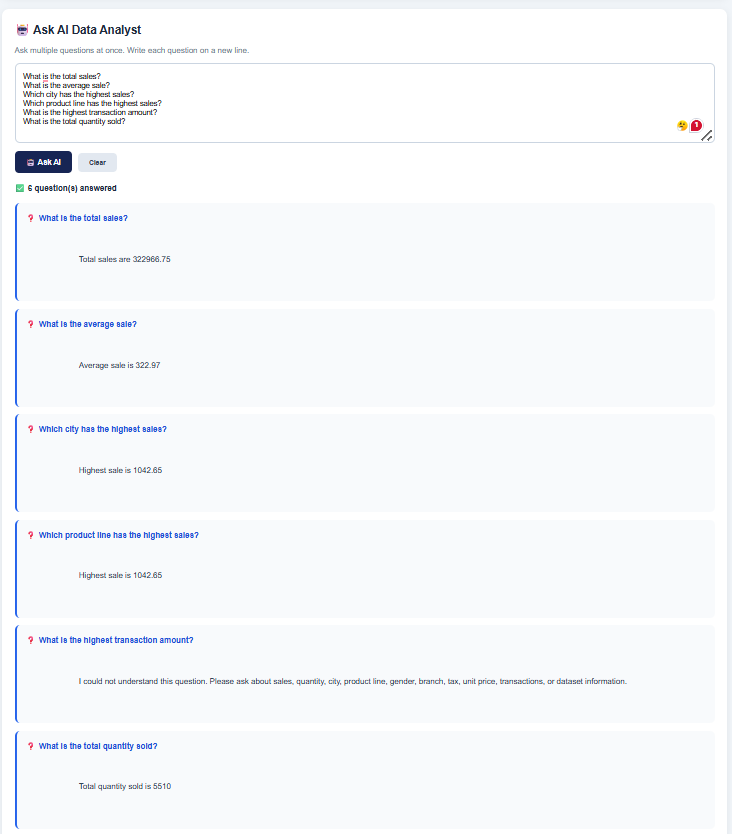

In [73]:
from IPython.display import Image, display

display(Image(filename="screenshots/dashboard.png"))

In [76]:
cd "C:\Users\disha\New folder"

C:\Users\disha\New folder


In [77]:
git add README.md screenshots

SyntaxError: invalid syntax (3984566496.py, line 1)

In [78]:
git commit -m "Add dashboard screenshots"

SyntaxError: invalid syntax (3607439773.py, line 1)

In [74]:
app.run(
    host="127.0.0.1",
    port=5004,
    debug=False,
    use_reloader=False
)

 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on http://127.0.0.1:5004
Press CTRL+C to quit
